# What Makes Chicago Crashes Severe?

CS 418 Introduction to Data Science, Progress Report

Team Data Driven: Salwa Majeed, Axel Alvarez, Hibatul Muqeet, Yaswin Chebrolu

GitHub repository: https://github.com/YaswinChebrolu/Chicago-Traffic-Crash-Trends

How to use this file: every section below has a short prompt in plain text. Replace the prompt with your own writing, put your name next to anything you built, and keep the section order. Code cells are marked with a comment saying whose they are.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import chi2_contingency

path = Path("data/cleaned_crashes.csv.gz")
if not path.exists():
    path = Path("../data/cleaned_crashes.csv.gz")

df = pd.read_csv(path, parse_dates=["crash_date"], low_memory=False)
print(df.shape)
df.head()

## 1. Project introduction

Chicago records more than 100,000 reported traffic crashes a year. Most cause only property damage, but a small share cause fatal or incapacitating injuries. Our project asks: what makes a Chicago traffic crash severe, and where and when are the most dangerous crashes? Understanding which conditions are linked to the most serious crashes can help the city decide where to focus safety improvements such as lighting, speed limits, and enforcement.

Data: We use the Traffic Crashes, Crashes dataset from the Chicago Data Portal, which contains reported crashes on Chicago city streets handled by the Chicago Police Department. After cleaning, we have 968,596 crashes from 2018 through October 2026, with details on the time, weather, lighting, road surface, posted speed limit, crash type, hit and run status, location, and injury outcome. We define a crash as severe if it involved a fatal or incapacitating injury. About 1.8 percent of crashes are severe, which makes severe crashes rare and harder to study.

Our hypotheses:

H1: Higher speed limits lead to more severe crashes.

H2: Darkness leads to more severe crashes.

H3: Bad weather raises crash counts but not severity.

H4: Hit and run crashes are more common at night.

So far we have tested H1 and H2 with chi square tests and visualizations, tested H4 with an hour of day analysis, and tested both sides of H3. The severity side came from the chi square tests, and for the crash count side we joined daily Chicago weather to daily crash counts and found that rain and snow days had about 4 to 5 percent more crashes than dry days.

## 2. Changes since the proposal

Our main question and four hypotheses have not changed since the proposal. Our scope has changed in the following ways.

Parts removed from our plan:

So far we have used only the Crashes table. We have not used the People or Vehicles tables, and we treat these as optional extras if time allows. We also replaced NOAA as our weather source (see below). Teammates: confirm whether anything else was dropped, or whether any of the planned analyses changed.

Parts added to our plan:

1. We limited the data to 2018 onward. Years before 2018 have far fewer records, which suggests incomplete reporting, and including them would have distorted any comparison across years.
2. We defined a severe crash as one with a fatal or incapacitating injury, so we could study the most serious outcomes and not just any injury.
3. We added a separate speed limit analysis (Viz 1b) to test H1 directly.
4. We added a hit and run analysis by hour of day (Viz 5) to test H4.
5. We decided to leave the injury, damage, and contributory cause columns out of any prediction model, because those are only known after the crash and would make a model look better than it really is.
6. We decided to compare severity as a rate (the share of crashes that are severe) and not as raw counts, because the data has no traffic volume information.
7. We added daily weather data (temperature, rain, and snow) from Open-Meteo for Chicago O’Hare, which we used in place of NOAA because it is free and needs no ordering. We joined it to daily crash counts to test the crash count side of H3.
8. We added a daily crash forecasting model (ML analysis 2) that predicts how many crashes happen each day from weather and calendar features, compared against a 7-day average baseline.

**Teammates: add anything new from your part, such as NOAA weather data, new features, or a new analysis.**

Why the scope changed:

Cleaning and exploring a dataset of about 1.1 million rows took more time than we expected, so the machine learning analyses were finished later than planned. We also switched from NOAA to Open-Meteo for weather data, since it was free and available right away and let us start the weather analysis without waiting on a data order. **Teammates: add any other reasons your work changed.**

## 3. Data

Data section (Salwa Majeed)

Source: Chicago Data Portal, Traffic Crashes, Crashes dataset.

What we did: We downloaded 1,108,694 crash records. We removed duplicates and rows with no injury information, leaving 1,106,297. We kept crashes from 2018 onward because earlier years (2013 to 2017) have far fewer records, which suggests incomplete reporting. That left 968,596 crashes from 2018 through October 2026 (2026 is a partial year).

Cleaning: We turned UNKNOWN values into blanks, set impossible coordinates (0) to blank, and set speed limits outside 5 to 70 mph to blank. After cleaning, about 5.2 percent of rows are missing lighting, 6.5 percent are missing weather, 0.5 percent are missing speed limit, and about 0.8 percent are missing coordinates.

New columns: severe (1 if the crash had a fatal or incapacitating injury, 0 otherwise), any_injury, hit_and_run, and crash_year. About 1.79 percent of crashes are severe.

Limits: The data has no traffic volume, so we compare severity rates and not crash counts. Freeway crashes are largely missing, and only reported crashes are included. The newest crashes may be missing later fatality updates.

Cleaning code: see notebooks/salwa_data_and_stats.ipynb in the repository.

**Other data we added (name the owner):**

In [24]:
# Data summary (Salwa)
print(df.shape)
print(df["crash_year"].value_counts().sort_index())
print(df["severe"].mean())

(968596, 53)
crash_year
2018    118728
2019    117499
2020     91860
2021    108519
2022    108119
2023    110493
2024    111805
2025    108902
2026     92671
Name: count, dtype: int64
0.01791562219955482


## 4. Exploratory data analysis

Show what the data looks like and note anything interesting or odd. Suggested pieces: crashes per year, crashes by hour of day and day of week, the share of severe crashes, and anything surprising.

Stats tests (Salwa Majeed): We ran chi square tests of severity against lighting, speed limit, and weather. All three were statistically significant, but the links were weak (Cramer's V of 0.035 for lighting, 0.034 for speed limit, and 0.011 for weather). Lighting and speed limit had the strongest links, and weather had the weakest. Each factor on its own explains only a small part of severity.

Weather results (Salwa Majeed): Severe crash rates were similar across most weather conditions (about 1.6 to 2.2 percent). Rain was slightly higher than clear weather (2.16 versus 1.89 percent), and snow was lower (1.24 percent). This is consistent with the severity part of H3, but H3 also says bad weather raises the number of crashes, which will be tested separately in the weather and forecasting analysis. Categories with fewer than about 1,000 crashes were not used for conclusions because their rates are unreliable.
**Add more here**

In [25]:
# Chi square tests (Salwa)
def chi_test(col):
    table = pd.crosstab(df[col], df["severe"])
    chi2, p, dof, expected = chi2_contingency(table)
    n = table.to_numpy().sum()
    cramers_v = (chi2 / (n * (min(table.shape) - 1))) ** 0.5
    return chi2, p, cramers_v

for col in ["lighting_condition", "posted_speed_limit", "weather_condition"]:
    chi2, p, v = chi_test(col)
    print(col, "| chi2 =", round(chi2, 1), "| p =", p, "| Cramer's V =", round(v, 3))

lighting_condition | chi2 = 1125.0 | p = 2.8722636276054842e-242 | Cramer's V = 0.035
posted_speed_limit | chi2 = 1089.2 | p = 2.543260338333816e-202 | Cramer's V = 0.034
weather_condition | chi2 = 114.1 | p = 8.104018172414319e-20 | Cramer's V = 0.011


In [26]:
for col, minimum in [("lighting_condition", 1000), ("weather_condition", 1000), ("posted_speed_limit", 300)]:
    t = df.groupby(col)["severe"].agg(severe_rate_percent="mean", crashes="count")
    t["severe_rate_percent"] = (t["severe_rate_percent"] * 100).round(2)
    print(t[t["crashes"] >= minimum].sort_values("severe_rate_percent", ascending=False), "\n")

                        severe_rate_percent  crashes
lighting_condition                                  
DARKNESS, LIGHTED ROAD                 2.70   211397
DAWN                                   2.29    16061
DARKNESS                               1.97    43345
DUSK                                   1.92    26474
DAYLIGHT                               1.57   620666 

                       severe_rate_percent  crashes
weather_condition                                  
OTHER                                 2.21     3162
RAIN                                  2.16    78651
CLEAR                                 1.89   758351
FOG/SMOKE/HAZE                        1.78     1457
SLEET/HAIL                            1.67     1081
CLOUDY/OVERCAST                       1.66    28633
FREEZING RAIN/DRIZZLE                 1.59     2573
SNOW                                  1.24    31366 

                    severe_rate_percent  crashes
posted_speed_limit                              
40.0   

EDA note (Salwa): Crashes follow a clear daily pattern. They are lowest in the early morning, at about 11,000 crashes at 4 am, then jump at 7 and 8 am with the morning commute. They dip slightly around 9 and 10 am, then climb through the day and peak in the mid to late afternoon, at about 75,000 crashes at 3 pm and almost as many at 4 and 5 pm. After 6 pm they fall steadily into the night. The busiest hour has roughly six to seven times as many crashes as the quietest one. This matters for our analysis for two reasons. First, because far fewer crashes happen at night, a rate (the share of crashes that are severe or hit and run) is a fairer comparison than a raw count. Second, our later results about nighttime, such as the higher hit and run share after dark, describe a larger share of a much smaller number of crashes.

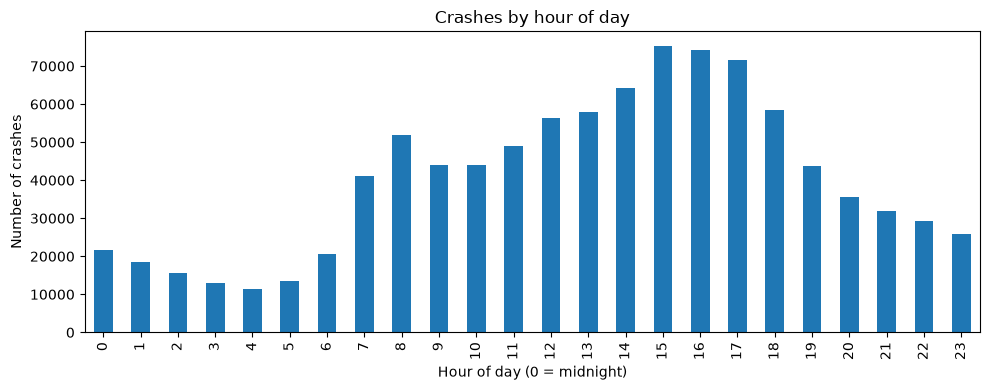

In [27]:
# EDA chart (Salwa): crashes by hour of day
counts = df["crash_hour"].value_counts().sort_index()
ax = counts.plot(kind="bar", figsize=(10, 4))
ax.set_xlabel("Hour of day (0 = midnight)")
ax.set_ylabel("Number of crashes")
ax.set_title("Crashes by hour of day")
plt.tight_layout()
plt.show()

In [ ]:
# EDA chart (Yaswin Chebrolu): average crashes per day by day of week and by month
d = df.copy()
d["date"] = d["crash_date"].dt.normalize()
daily_counts = d.groupby("date").size().iloc[:-14]   # last 14 days are still being reported

dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_dow = daily_counts.groupby(daily_counts.index.day_of_week).mean()
by_dow.index = dow_names

# Months: use full, typical years only (leave out 2020 and the partial year 2026)
typical = daily_counts[~daily_counts.index.year.isin([2020, 2026])]
by_month = typical.groupby(typical.index.month).mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
by_dow.plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Average crashes per day by day of week")
axes[0].set_ylabel("Crashes per day")
by_month.plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Average crashes per day by month (2020 and 2026 left out)")
axes[1].set_xlabel("Month")
plt.tight_layout()
plt.show()

print("Typical day:", round(daily_counts.mean()), "| quietest:", daily_counts.min(), "| busiest:", daily_counts.max())
print(by_dow.round(0))
print(by_month.round(0))

In [28]:
# Other exploration charts go here (add the owner's name in a comment)


## 5. Visualizations
Viz 1 (Salwa): Crashes in daylight were the least likely to be severe (1.57 percent). Crashes at dawn, dusk, and in darkness were all more likely to be severe. Darkness on a lighted road had the highest rate (2.70 percent), higher than darkness on an unlit road (1.97 percent). This partly supports H2. The lighted road result may mean road type or traffic speed matters too, which we can look at with our models. We thought this was interesting because lighting is something the city can change by adding or improving street lights, so a link between darkness and severity points to a possible fix.

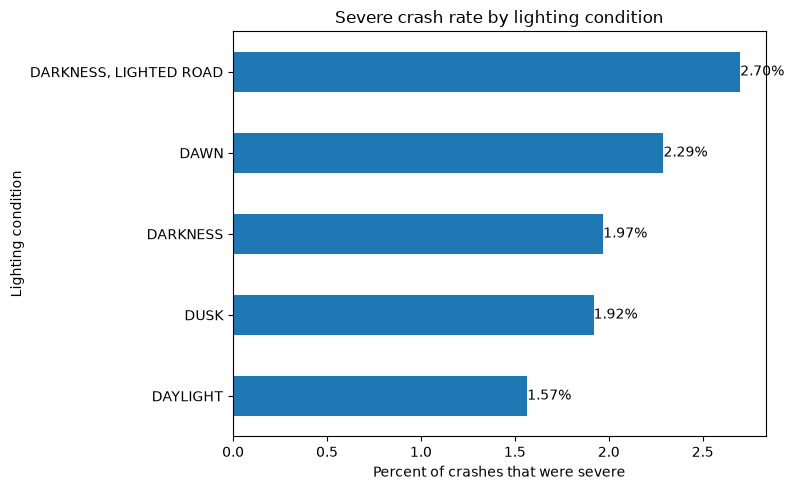

In [29]:
# Viz 1 (Salwa)
stats = df.groupby("lighting_condition")["severe"].agg(["mean", "count"])
stats = stats[stats["count"] >= 1000]
rate = (stats["mean"] * 100).sort_values()

ax = rate.plot(kind="barh", figsize=(8, 5))
ax.bar_label(ax.containers[0], fmt="%.2f%%")
ax.set_xlabel("Percent of crashes that were severe")
ax.set_ylabel("Lighting condition")
ax.set_title("Severe crash rate by lighting condition")
plt.tight_layout()
plt.show()

Viz 1b (Salwa Majeed): The severe crash rate generally rises with the posted speed limit, from about 0.6 percent at 10 mph to 1.86 percent at 30 mph and 3.58 percent at 40 mph. This supports H1, although the increase is not perfectly smooth above 40 mph. Speed limits with fewer than 300 crashes were left out because their rates are unreliable. We thought this was interesting because speed limits are a policy choice, so a clear link between speed limit and severity could inform where limits should be lowered.

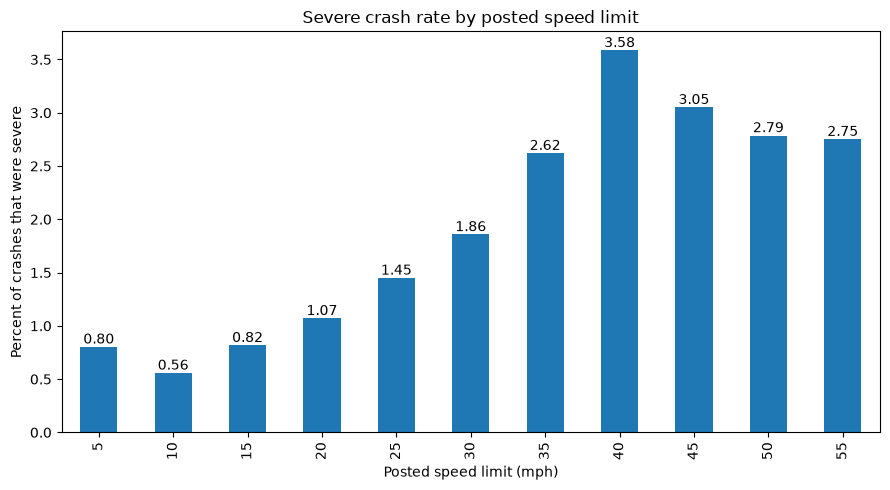

In [30]:
# Viz 1b (Salwa)
speed = df.groupby("posted_speed_limit")["severe"].agg(["mean", "count"])
speed = speed[speed["count"] >= 300]
speed_rate = speed["mean"] * 100
speed_rate.index = speed_rate.index.astype(int)

ax = speed_rate.plot(kind="bar", figsize=(9, 5))
ax.set_xlabel("Posted speed limit (mph)")
ax.set_ylabel("Percent of crashes that were severe")
ax.set_title("Severe crash rate by posted speed limit")
ax.bar_label(ax.containers[0], fmt="%.2f")
plt.tight_layout()
plt.show()

Viz 2 (member name): [Hypothesis tested, why it is interesting, and what the chart shows. Suggested: which features matter most for predicting severe crashes.]

In [31]:
# Viz 2 (member name)


Viz 3 (Yaswin Chebrolu): We tested H3, that bad weather raises crash counts but not severity. We thought this was interesting because weather is the one factor in our project that nobody can change, so it shows whether severity is mostly about conditions people can fix (lighting, speed limits) or about luck. Severe crash rates ranged from 1.24 percent in snow to 2.40 percent in blowing snow, around an overall rate of 1.79 percent. Bad weather did bring more crashes per day: rain days averaged about 310 crashes and snow days about 307, compared with about 295 on dry days, an increase of roughly 4 to 5 percent. Severity did not follow the same pattern. Snow was below the overall severe rate, and rain was only slightly above it. This supports H3: bad weather nudges up how many crashes happen but does not consistently make them worse. Limitations: weather comes from one station (O’Hare) for the whole city, and rare conditions like blowing snow have few crashes, so their rates are less reliable.

In [32]:
# Viz 3 (Yaswin Chebrolu): crashes and severity by weather condition
import requests

# Count crashes per day (drop the last 14 days, which are still being reported)
df["date"] = df["crash_date"].dt.normalize()
daily = df.groupby("date").size().rename("crashes").to_frame()
daily = daily.reindex(pd.date_range(daily.index.min(), daily.index.max(), freq="D"), fill_value=0)
daily.index.name = "date"
daily = daily.iloc[:-14]

# Daily weather for Chicago O'Hare from Open-Meteo (free). Saved so it only downloads once.
weather_file = path.parent / "chicago_weather.csv"
if weather_file.exists():
    weather = pd.read_csv(weather_file, parse_dates=["date"])
else:
    r = requests.get("https://archive-api.open-meteo.com/v1/archive", params={
        "latitude": 41.9742, "longitude": -87.9073,
        "start_date": daily.index.min().strftime("%Y-%m-%d"),
        "end_date": daily.index.max().strftime("%Y-%m-%d"),
        "daily": "temperature_2m_mean,precipitation_sum,snowfall_sum",
        "timezone": "America/Chicago"}, timeout=60)
    r.raise_for_status()
    d = r.json()["daily"]
    weather = pd.DataFrame({"date": pd.to_datetime(d["time"]), "temp_c": d["temperature_2m_mean"],
                            "precip_mm": d["precipitation_sum"], "snow_cm": d["snowfall_sum"]})
    weather.to_csv(weather_file, index=False)

# Join weather to daily crash counts
data = daily.join(weather.set_index("date"), how="inner").dropna()
data["dow"] = data.index.day_of_week
data["month"] = data.index.month
data["year"] = data.index.year
data["prev7_avg"] = data["crashes"].shift(1).rolling(7).mean()
data = data.dropna()

# Left and right charts: crash count and severe rate by weather condition
w = df.copy()
w["weather_condition"] = w["weather_condition"].astype(str).str.upper().str.strip()
w = w[~w["weather_condition"].isin(["UNKNOWN", "OTHER", "NAN", ""])]
by_wx = (w.groupby("weather_condition")
           .agg(crashes=("severe", "size"), severe_pct=("severe", lambda s: s.mean() * 100))
           .query("crashes >= 300").sort_values("crashes"))
overall = w["severe"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
axes[0].barh(by_wx.index, by_wx["crashes"])
axes[0].set_xscale("log")
axes[0].set_title("Crashes by weather condition (log scale)")
axes[0].set_xlabel("Number of crashes")
axes[1].barh(by_wx.index, by_wx["severe_pct"])
axes[1].axvline(overall, color="black", linestyle="--", label=f"Overall: {overall:.2f}%")
axes[1].set_title("Percent of crashes that were severe")
axes[1].set_xlabel("Severe crashes (%)")
axes[1].legend()
plt.tight_layout()
plt.show()
print(by_wx.round(2))

# Average crashes per day on dry, rain, and snow days
def weather_group(row):
    if row["snow_cm"] >= 0.5:
        return "Snow day"
    if row["precip_mm"] >= 1:
        return "Rain day"
    return "Dry day"

data["wx_group"] = data.apply(weather_group, axis=1)
per_day = (data.groupby("wx_group")["crashes"].agg(["mean", "count"])
           .rename(columns={"mean": "avg crashes per day", "count": "days"})
           .reindex(["Dry day", "Rain day", "Snow day"]))
per_day["avg crashes per day"].plot.bar(figsize=(6, 4), rot=0)
plt.title("Average crashes per day by weather")
plt.ylabel("Crashes per day")
plt.tight_layout()
plt.show()
print(per_day.round(1))

Viz 4 (member name): [Hypothesis tested, why it is interesting, and what the chart shows. Suggested: a map of crash hotspots.]

In [33]:
# Viz 4 (member name)


Viz 5 (Salwa): We tested H4, that hit and run crashes are more common at night. We thought this was an interesting hypothesis because a hit and run is both a safety problem and an accountability problem, and knowing when they cluster could help target enforcement and lighting. Hit and run crashes made up 41.95 percent of crashes between 8 pm and 5:59 am, compared with 27.34 percent during the day. The share rises through the evening, peaks at about 49 percent around 3 am, and falls quickly after 5 am to a low of about 26 percent in the early afternoon. A chi square test confirmed the difference is statistically significant (chi square of about 16,895, p value far below 0.05), and the gap of about 15 percentage points is large, not just a product of the big sample size. This supports H4. Limitations: this measures the share of crashes that were hit and run at each hour, not the number of hit and run crashes, since there are far fewer crashes overall late at night. Also, crashes with a blank hit and run field were counted as not hit and run, so the true shares may be slightly higher.

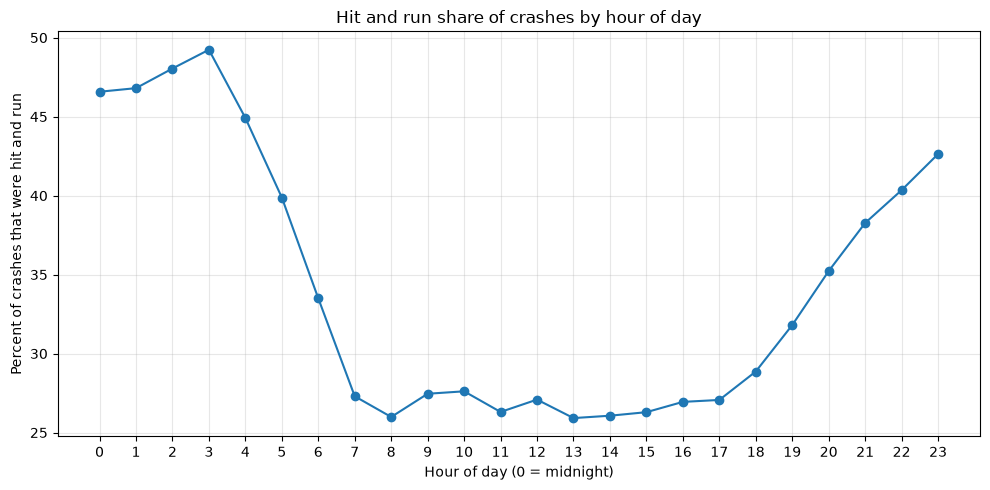

is_night
False    27.34
True     41.95
Name: hit_and_run, dtype: float64
chi2 = 16895.4 | p = 0.0


In [34]:
# Viz 5 (Salwa)
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency


# Viz 5 (Salwa): hit and run share by hour of day
hr = df.groupby("crash_hour")["hit_and_run"].mean() * 100

ax = hr.plot(kind="line", marker="o", figsize=(10, 5))
ax.set_xticks(range(0, 24))
ax.set_xlabel("Hour of day (0 = midnight)")
ax.set_ylabel("Percent of crashes that were hit and run")
ax.set_title("Hit and run share of crashes by hour of day")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Night (8 pm to 5:59 am) versus day
df["is_night"] = df["crash_hour"].isin(list(range(20, 24)) + list(range(0, 6)))
print((df.groupby("is_night")["hit_and_run"].mean() * 100).round(2))

table = pd.crosstab(df["is_night"], df["hit_and_run"])
chi2, p, dof, expected = chi2_contingency(table)
print("chi2 =", round(chi2, 1), "| p =", p)


## 6. Machine learning analyses

At least two. For each one: the member responsible, the question, the baseline, the model, the results, and a plain language interpretation.

### ML analysis 1 (member name)

Question: [for example, can we predict whether a crash is severe from conditions known at the time of the crash?]

Features used: [list them, and note that injury, damage, and contributory cause columns were left out because they are only known after the crash]

Baseline: [for example, always predict not severe]

Models: [for example, logistic regression and random forest]

Results: [a small table of precision, recall, F1, and AUC for the baseline and each model]

Interpretation: [what the results mean in plain words, and what the model got right or wrong]

In [35]:
# ML analysis 1 (member name)


ML analysis 2 (Yaswin Chebrolu)

Question: Can we forecast daily crash counts using weather and calendar features?

Features used: daily mean temperature, rainfall, snowfall, day of week, and month. One version also used the average crashes over the previous 7 days. Daily weather came from Open-Meteo for Chicago O’Hare.

Baselines: (1) predict the average of the previous 7 days, and (2) predict the overall training average every day.

Models: linear regression and random forest. We trained on 2018 through 2025 and tested on 2026, so the model never sees the future. The test year has about 306 crashes per day on average.

Results (mean absolute error, crashes per day, lower is better):

Model: Error
Baseline: previous 7-day average: 36.1
Random forest (weather + calendar): 30.2
Random forest (weather + calendar + previous 7-day average): 29.9

Interpretation: Our best model was off by about 30 crashes per day, compared with 36 for the 7-day baseline, so weather and calendar information beats simply guessing from recent days. Adding the recent crash level only improved the error by about 0.3 crashes a day, so weather and the calendar carry most of the useful signal. The model still misses by roughly 10 percent of a typical day, so it is useful but not precise. One limitation is that the model uses actual weather rather than a forecast, and the calendar features are included alongside weather, so we can’t say how much of the improvement comes from weather alone.

In [36]:
# ML analysis 2 (Yaswin Chebrolu): forecast daily crash counts
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

test_year = data["year"].max()
train = data[data["year"] < test_year]
test = data[data["year"] == test_year]

WEATHER = ["temp_c", "precip_mm", "snow_cm"]
def make_X(frame, extra=()):
    X = frame[WEATHER + list(extra) + ["dow", "month"]].copy()
    return pd.get_dummies(X, columns=["dow", "month"], dtype=float)

preds = {
    "Baseline: previous 7-day average": test["prev7_avg"],
    "Baseline: overall training average": pd.Series(train["crashes"].mean(), index=test.index),
}

X_tr, X_te = make_X(train), make_X(test)
X_te = X_te.reindex(columns=X_tr.columns, fill_value=0)
preds["Linear regression (weather + calendar)"] = pd.Series(
    LinearRegression().fit(X_tr, train["crashes"]).predict(X_te), index=test.index)
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1).fit(X_tr, train["crashes"])
preds["Random forest (weather + calendar)"] = pd.Series(rf.predict(X_te), index=test.index)

X_tr2, X_te2 = make_X(train, ["prev7_avg"]), make_X(test, ["prev7_avg"])
X_te2 = X_te2.reindex(columns=X_tr2.columns, fill_value=0)
rf2 = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1).fit(X_tr2, train["crashes"])
preds["Random forest (weather + calendar + prev 7-day avg)"] = pd.Series(rf2.predict(X_te2), index=test.index)

mean_daily = test["crashes"].mean()
summary = pd.Series({k: mean_absolute_error(test["crashes"], v) for k, v in preds.items()},
                    name="MAE (crashes/day)").sort_values().to_frame()
summary["MAE as % of average day"] = (summary["MAE (crashes/day)"] / mean_daily * 100).round(1)
summary["MAE (crashes/day)"] = summary["MAE (crashes/day)"].round(1)
print("Average crashes per day in the test year:", round(mean_daily, 1))
print(summary)

summary["MAE (crashes/day)"].sort_values(ascending=False).plot.barh(figsize=(8, 4))
plt.title("Prediction error on the test year (lower is better)")
plt.xlabel("Mean absolute error (crashes per day)")
plt.tight_layout()
plt.show()

## 7. Reflection

What is the most challenging part of the project so far?

The biggest challenge has been the size and messiness of the data. The raw file has about 1.1 million rows with mixed data types, "UNKNOWN" values, bad coordinates, and dates that were very slow to parse until we gave the exact format. The file is also too large for GitHub, so we share the cleaned data through Google Drive and keep the cleaning code in the repository. A second challenge is that severe crashes are rare (about 1.8 percent), which makes them hard to study and predict. 

For the weather and forecasting analysis, the main challenge was lining up two different data sources. Crashes are recorded one row at a time, while weather is daily, so we had to count crashes per day, fill in days with no crashes, and join the two by date. We also had to be careful with the most recent weeks, because crashes are still being reported, which makes the last days look artificially low. We dropped the last 14 days for that reason. Finally, a forecast has to be tested on the future, so we trained on earlier years and tested on 2026 and not on a random split.
**Teammates: add the challenges you ran into in your own analyses.**

What are our initial insights?

Speed limit and lighting have the strongest links to severity, but all links are weak on their own (Cramer's V of about 0.035 for lighting, 0.034 for speed limit, and 0.011 for weather). Daylight crashes were the least likely to be severe (1.57 percent), and darkness on a lighted road was the highest (2.70 percent). The severe rate generally rises with the posted speed limit, from about 1.86 percent at 30 mph to 3.58 percent at 40 mph. Weather has the weakest link, with rain slightly higher than clear weather (2.16 versus 1.89 percent) and snow lower (1.24 percent). Hit and run crashes made up 41.95 percent of crashes at night (8 pm to 5:59 am) versus 27.34 percent during the day, peaking at about 49 percent around 3 am. 

Bad weather raises crash counts only a little: rain days averaged about 310 crashes and snow days about 307, compared with about 295 on dry days, an increase of roughly 4 to 5 percent. It does not consistently raise severity, since snow was below the overall severe rate and rain was only slightly above it. A model using weather and calendar features predicted daily crash counts better than a 7-day average baseline (error of about 30 versus 36 crashes per day), though it still missed by roughly 10 percent of a typical day.
**Teammates: add your insights**

Are there concrete results we can show at this point? If not, why not?

[answer]

Going forward, what are the biggest problems we face?

The data has no traffic volume, so we can compare severity rates but not true risk per driver or per mile. Severe crashes are rare, so models will need class weights or a similar method and must be judged with precision, recall, and AUC instead of accuracy. About 5 percent of rows are missing lighting and about 6.5 percent are missing weather. Freeway crashes are largely missing from the dataset, which may understate crashes at the highest speed limits. We also still need to join outside weather data and finish the remaining analyses in time.

We also still need to finish the remaining analyses in time. Our weather data comes from a single station (O’Hare) for the whole city, so it can miss local differences, and our forecasting model uses actual weather and not a weather forecast.

**Teammates: add any technical problems from your parts.**

Are we on track? If not, which parts need more time?

We are mostly on track. The data preparation, statistical tests, and the first visualizations are done, and the two required machine learning analyses are being completed tonight. The remaining visualizations and the interactive map dashboard will need the most time over the next month. **Team: confirm the current status of each remaining task and who owns it.**

Given our initial exploration, is it worth proceeding? If not, how will we move forward?

Yes. The exploration shows clear patterns, such as the higher severe rate in the dark and at higher speed limits, and the much higher hit and run share at night. Since each factor is only weakly linked to severity by itself, the next step is to combine them in a model and see how well they predict severe crashes together. If predictions turn out weak, we will report that honestly and focus on explaining which conditions matter most. We may also add the People or Vehicles tables if time allows. **Teammates: add anything from your results that changes the plan.**

## 8. Next steps

Our plan for the next month:

**Add more here**

By November 30: Finish the presentation slides (due November 30 at 11:59 pm). Everyone

By December 7: Write the final report and make sure the code, cleaned data reference, and every member's visualizations and analyses are in the repository.